# Freshness-AI: Fruit Type & Freshness Classification

<img src="../data/sample/fresh_apple.jpg" width="300" height="250">
<img src="../data/sample/rotten_apple.jpg" width="300" height="250">

**Freshness-AI** is a computer vision application that identifies a fruit from a single photo and tells whether it is **fresh or rotten**. It recognises 8 fruits (apple, banana, grape, guava, jujube, orange, pomegranate and strawberry), each in fresh and rotten condition, for **16 classes** in total.

**Motivation:** a large share of fresh produce is wasted before it reaches consumers, often because spoilage is spotted too late. A quick, phone-based freshness check can help market vendors, grocers and households sort produce early and reduce waste.

**This notebook covers:**
1. **Data acquisition:** loading the Fresh & Rotten Fruits dataset (3,200 images, 200 per class)
2. **Data exploration:** visualising class balance, colour and image characteristics
3. **Preprocessing:** resizing, normalisation, train/validation/test split and data augmentation
4. **Model creation:** transfer learning from a pretrained CNN with regularisation and early stopping
5. **Evaluation:** accuracy, loss, precision, recall, F1-score and a confusion matrix
6. **Prediction:** testing the model on individual images
7. **Saving the model** for deployment and retraining


In [1]:
import os
import shutil
import tensorflow as tf
import tensorboardX
import random
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
from sklearn.metrics import (precision_score,
                             accuracy_score,
                             f1_score,
                             recall_score,
                             roc_auc_score,
                             confusion_matrix,
                             classification_report,
                             ConfusionMatrixDisplay
                             )

I0000 00:00:1795240821.130054  457246 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795240821.130628  457246 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795240821.186803  457246 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795240823.426297  457246 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

## Step 1: Open and Display 9 random images in the dataset

In [2]:
SEED = 42

In [3]:
random.seed(SEED)

image_folder = Path().cwd().resolve().parent/"data"/"raw_data"/"images"
all_images = [image for image in image_folder.rglob("*") if image.suffix.lower() in {".jpg", ".jpeg", ".png"}]
images_select = random.sample(all_images, 9)


In [4]:
all_rotten_fruits = [
    img_rot for img_rot in image_folder.rglob("*")
    if img_rot.suffix.lower() in {".jpeg", ".jpg", ".png"}
    and img_rot.parent.name.startswith("rotten_")
]
all_fresh_fruits = [img_fresh for img_fresh in image_folder.glob("fresh_*/*") if img_fresh.suffix.lower() in {".jpeg", ".jpg", ".png"}]
class_names = sorted(img_classes.name for img_classes in image_folder.iterdir() if img_classes.is_dir())
print(f"Dataset contains: {len(all_images)} images")
print(f"Number of rotten fruits: {len(all_rotten_fruits)}")
print(f"Number of fresh fruits: {len(all_fresh_fruits)}")
print(f"Image classes:\n{class_names}")

Dataset contains: 3200 images
Number of rotten fruits: 1600
Number of fresh fruits: 1600
Image classes:
['fresh_apple', 'fresh_banana', 'fresh_grape', 'fresh_guava', 'fresh_jujube', 'fresh_orange', 'fresh_pomegranate', 'fresh_strawberry', 'rotten_apple', 'rotten_banana', 'rotten_grape', 'rotten_guava', 'rotten_jujube', 'rotten_orange', 'rotten_pomegranate', 'rotten_strawberry']


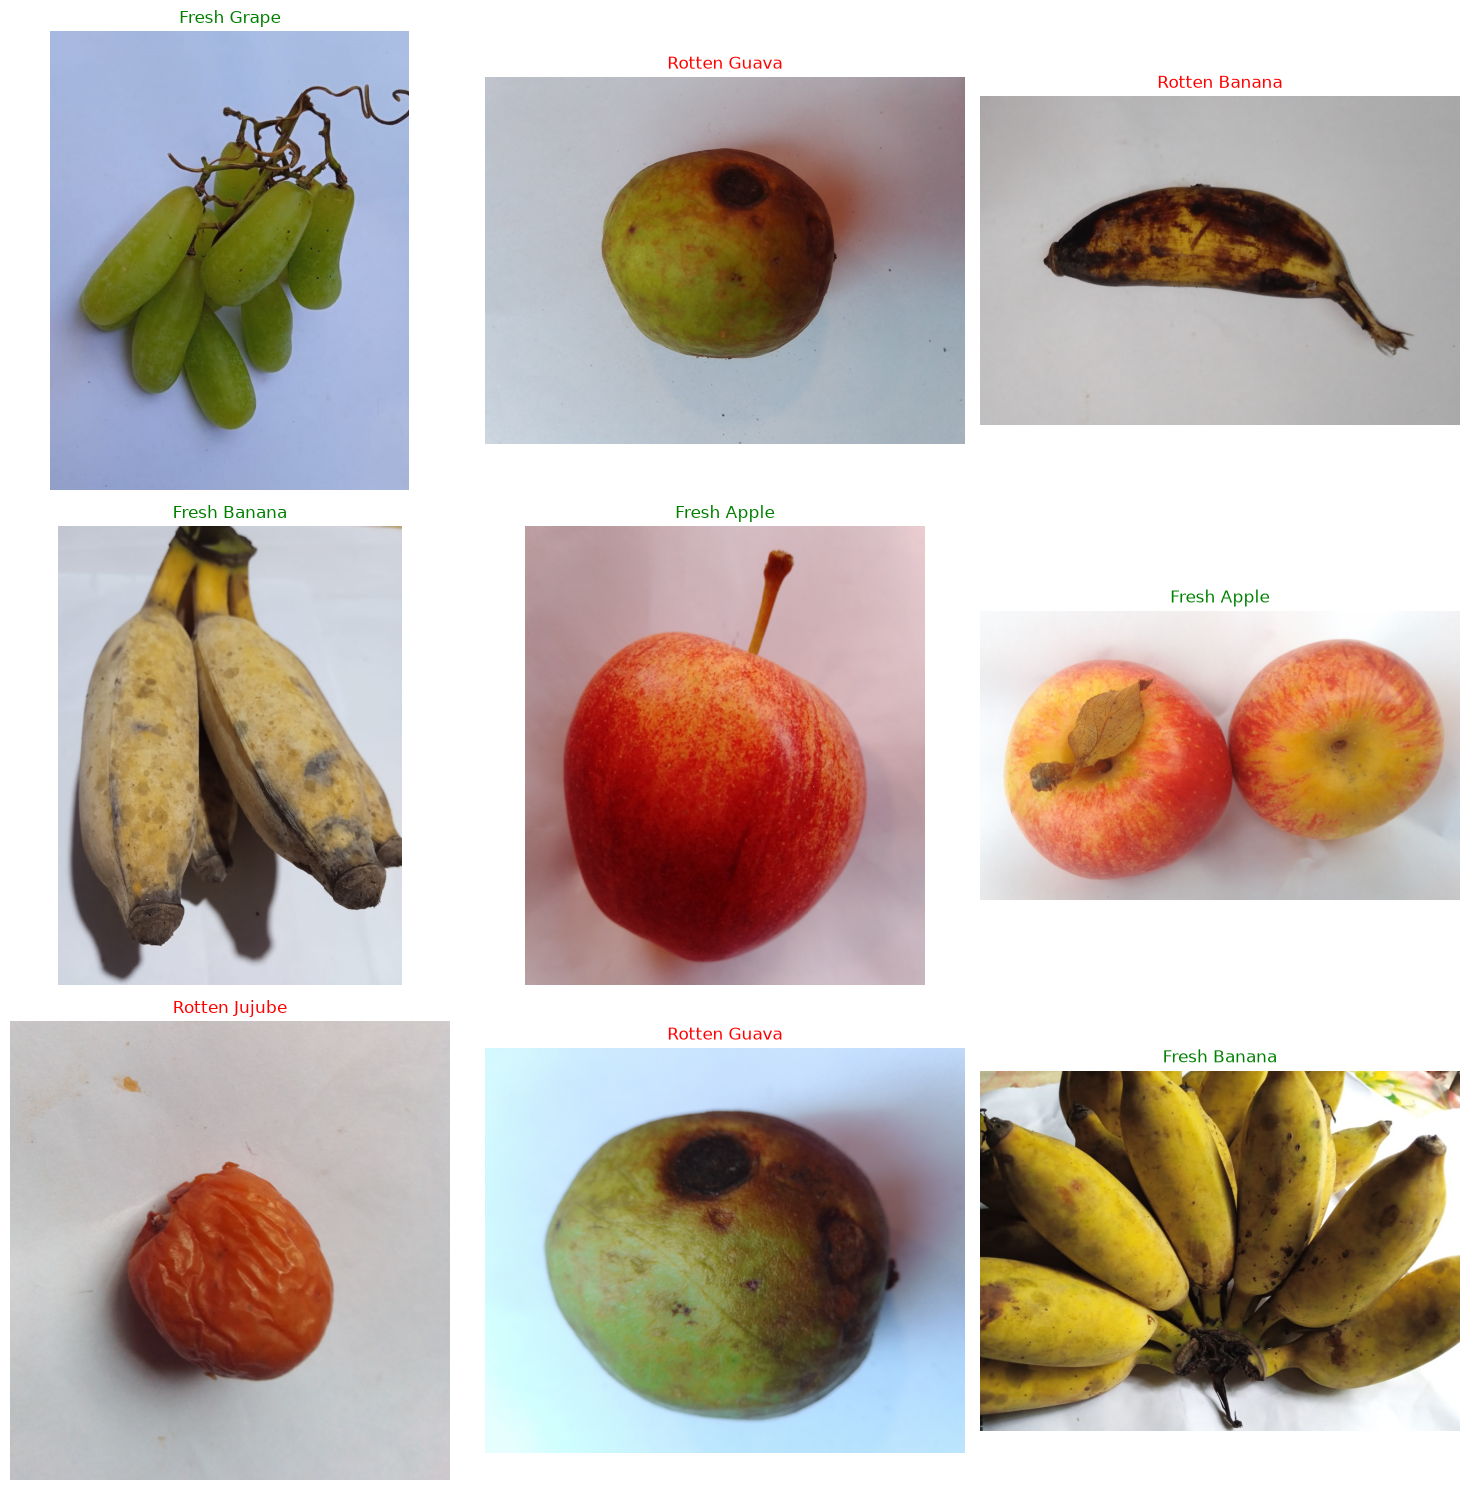

In [5]:
fig, axes = plt.subplots(3, 3, figsize=(15, 15))

for ax, path in zip(axes.flat, images_select):
    ax.imshow(Image.open(path))
    name = path.parent.name
    ax.set_title(name.replace("_", " ").title(),
             color="green" if name.startswith("fresh") else "red")

    ax.axis("off")

plt.tight_layout()
plt.show()


## Step 2: Split images inside raw_data/images into training, validation, testing

In [6]:
def group_images_by_class(image_folder:Path) -> tuple[dict, list]:
    image_classes = {}
    for folder in sorted(image_folder.iterdir()):
        if folder.is_dir():
            image_classes[folder.name] = sorted(
                image for image in folder.iterdir()
                if image.suffix.lower() in {".jpg", ".jpeg", ".png"}
                )
    classes = list(image_classes.keys())

    return image_classes, classes

In [7]:
all_images, classes = group_images_by_class(image_folder=image_folder)

def spliting(all_images: dict[str, list], classes: list[str] = None, seed: int = 42):
    """
    Split each class into train/val/test: 65% / 15% / 20%.
    """
    train_df, val_df, test_df = {}, {}, {}
    rng = random.Random(seed)

    for key, value in sorted(all_images.items()):
        items = sorted(value)
        rng.shuffle(items)

        size = len(items)
        train_end = int(size * 0.65)
        val_end = int(size * 0.80)

        train_df[key] = items[:train_end]
        val_df[key] = items[train_end:val_end]
        test_df[key] = items[val_end:]

    return train_df, val_df, test_df, classes

In [8]:
train_df, val_df, test_df, classes = spliting(all_images, classes)

print("Number of Images per classs:")
pd.DataFrame({
    "train": {key: len(value) for key, value in train_df.items()},
    "val":   {key: len(value) for key, value in val_df.items()},
    "test":  {key: len(value) for key, value in test_df.items()},
})


Number of Images per classs:


,train,val,test
fresh_apple,130,30,40
fresh_banana,130,30,40
fresh_grape,130,30,40
fresh_guava,130,30,40
fresh_jujube,130,30,40
fresh_orange,130,30,40
fresh_pomegranate,130,30,40
fresh_strawberry,130,30,40
rotten_apple,130,30,40
rotten_banana,130,30,40


In [9]:
def copy_split(split: dict[str, list], dest_root: Path):
    shutil.rmtree(dest_root, ignore_errors=True)
    jobs = []
    for class_name, files in split.items():
        dest = dest_root / class_name
        dest.mkdir(parents=True, exist_ok=True)
        jobs += [(file, dest / file.name) for file in files]

    with ThreadPoolExecutor(max_workers=3) as pool:
        list(pool.map(lambda job: shutil.copy2(*job), jobs))


In [10]:
data_dir = image_folder.parent.parent
copy_split(train_df, data_dir / "train")
copy_split(val_df,   data_dir / "validation")
copy_split(test_df,  data_dir / "test")
print("Complete...")

Complete...


## Step 3: Processing Images:
- Load images as tensors
- Resize and normalize images
- Augmentation (for training only)
- Speed up data pipeline

### Many of these images may have come from different cameras and may have different size. This step will check the distribution of width and height in all images and decide appropriate strategies. This will be done through the ratio between width and height

In [11]:
rows = []
for class_name, files in all_images.items():
    for path in files:
        with Image.open(path) as image:
            width, height = image.size
        rows.append({
            "class":class_name,
            "fruit":class_name.split("_", 1)[1],
            "state":class_name.split("_", 1)[0],
            "width": width,
            "height":height,
            "aspect_ratio":width / height
        })
sizes = pd.DataFrame(rows)
sizes.describe()

,width,height,aspect_ratio
count,3200.000000,3200.000000,3200.000000
mean,2290.565938,2135.965625,1.084720
std,1064.442339,923.097362,0.251219
min,251.000000,301.000000,0.382372
25%,1200.000000,1260.250000,0.917138
50%,2492.500000,2330.000000,1.066004
75%,3081.000000,2820.000000,1.263836
max,4160.000000,4160.000000,2.519119


### Plotting  distribution by classes

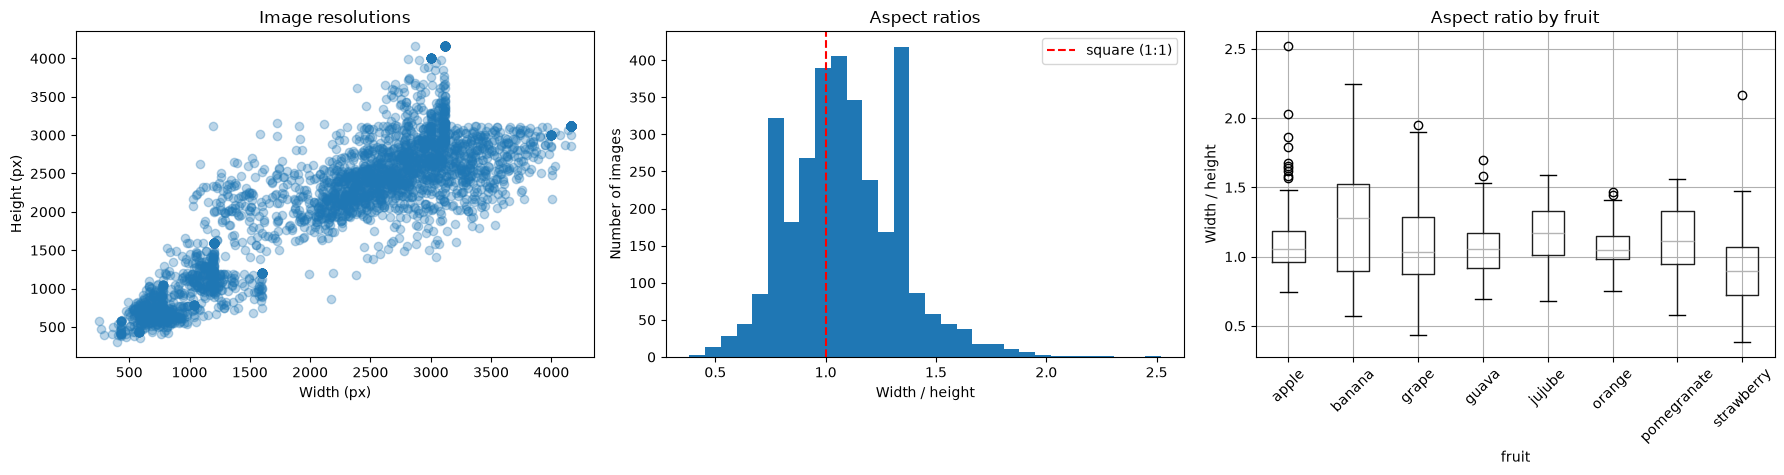

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# width vs height: shows how many distinct resolutions there are
axes[0].scatter(sizes["width"], sizes["height"], alpha=0.3)
axes[0].set(xlabel="Width (px)", ylabel="Height (px)", title="Image resolutions")

# aspect-ratio histogram: 1.0 = square, >1 = wide, <1 = tall
axes[1].hist(sizes["aspect_ratio"], bins=30)
axes[1].axvline(1.0, color="red", linestyle="--", label="square (1:1)")
axes[1].set(xlabel="Width / height", ylabel="Number of images", title="Aspect ratios")
axes[1].legend()

# aspect ratio per fruit: does one fruit come in a different shape?
sizes.boxplot(column="aspect_ratio", by="fruit", ax=axes[2], rot=45)
axes[2].set(title="Aspect ratio by fruit", ylabel="Width / height")

plt.suptitle("")
plt.tight_layout()
plt.show()


Images in this dataset are from different sizes. So resizing them to a fixed size is a required preprocessing step. Stretching images where ratio of width/height between 0.8 to 1.25 distorts images only slighly. Resizing images where ratio lays between 1.33 (4:3) or 1.78 (16:9), typical phone photos size, might make fruits look squashed. crop_to_aspect_ratio=True will be set to center fruits in the middle

In [13]:
sizes.groupby("class")[["width", "height", "aspect_ratio"]].mean().round(2)

,width,height,aspect_ratio
class,,,
fresh_apple,2640.36,2468.68,1.09
fresh_banana,1184.03,1147.54,1.10
fresh_grape,798.37,743.82,1.10
fresh_guava,1215.24,1274.44,0.98
fresh_jujube,2880.14,2518.32,1.15
fresh_orange,3142.46,2892.21,1.10
fresh_pomegranate,2492.30,2455.89,1.03
fresh_strawberry,1850.84,2341.26,0.78
rotten_apple,3099.17,2918.95,1.08


In [14]:
IMAGE_SIZE = (222, 224)
BATCH = 32
train_data = tf.keras.utils.image_dataset_from_directory(
    data_dir/"train",
    image_size=IMAGE_SIZE,
    batch_size=BATCH,
    label_mode="categorical",
    shuffle=True,
    seed=SEED
)
val_data = tf.keras.utils.image_dataset_from_directory(
    data_dir/"validation",
    image_size=IMAGE_SIZE,
    batch_size=BATCH,
    label_mode="categorical",
    shuffle=False,
    seed=SEED
    )

test_data = tf.keras.utils.image_dataset_from_directory(
    data_dir/"test",
    image_size=IMAGE_SIZE,
    batch_size=BATCH,
    label_mode="categorical",
    shuffle=False,
    seed=SEED
)
train_data
test_data

Found 2080 files belonging to 16 classes.
Found 480 files belonging to 16 classes.
Found 640 files belonging to 16 classes.


E0000 00:00:1795240938.508146  457246 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1795240938.508886  461421 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
W0000 00:00:1795240938.529204  457246 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 222, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 16), dtype=tf.float32, name=None))>

### Augment training set

In [62]:
augment = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal'),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(0.1)
], name="augmentation")

## Step 4: Training Freshness-AI using MobileNetV2 pretrained on ImageNet
**Why a pretrained model?** With only 130 training images per class **(2,080 in total)**, training a deep convolutional neural network from scratch would likely overfit and generalise poorly to the validation and test data. Instead, we use transfer learning, since features learned on a large dataset transfer well to new tasks with limited data (Yosinski et al., 2014; TensorFlow, n.d.). It works in two stages:

**Feature extraction:** the pretrained convolutional base, including its batch-normalisation layers, stays frozen, and only a new 16-class classification head is trained.

**Fine-tuning:** the top layers of the base are then unfrozen and trained with a very small learning rate (see Step 5).

**MobileNetV2** (Sandler et al., 2018) suits this project because it is lightweight. Our full model has 2,278,480 parameters, of which only 20,496 are trainable during feature extraction. Trained on ImageNet (around 1.28 million images, 1,000 classes; Deng et al., 2009; Russakovsky et al., 2015), it reaches about 71% top-1 accuracy (Keras Team, n.d.). It also gives much faster inference and retraining than deeper networks like ResNet50 (He et al., 2016), which has around 25.6M parameters (Keras Team, n.d.). That matters for a mobile-friendly web app and for retraining on user-uploaded images.

In [63]:
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_data.cache().shuffle(1000, seed=SEED).prefetch(AUTOTUNE)
val_ds   = val_data.cache().prefetch(AUTOTUNE)
test_ds  = test_data.cache().prefetch(AUTOTUNE)

In [64]:
def mobilenet_model():
    base_model = tf.keras.applications.MobileNetV2(
        input_shape=(222, 224, 3),
        include_top=False,
        weights="imagenet",
    )
    base_model.trainable = False
    inputs = tf.keras.Input(shape=(222, 224, 3))
    x = augment(inputs)
    x = tf.keras.layers.Rescaling(1/127.5, offset=-1)(x)
    x = base_model(x, training=False)
    x = tf.keras.layers.GlobalAvgPool2D()(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    outputs = tf.keras.layers.Dense(len(classes), activation="softmax")(x)
    
    model = tf.keras.Model(inputs, outputs, name="freshness_mobilenet")
    return model

model = mobilenet_model()
model.summary()

/tmp/ipykernel_8744/2249496710.py:2: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = tf.keras.applications.MobileNetV2(


Model: "freshness_mobilenet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 222, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 222, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 222, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │        20,496 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,278,480 (8.69 MB)

 Trainable params: 20,496 (80.06 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
def compile_model(model:tf.keras.Model):
    """Compile the model and run"""
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss=tf.keras.losses.CategoricalCrossentropy(),
        metrics=[
            "accuracy",
            tf.keras.metrics.Precision(name="Precision"),
            tf.keras.metrics.Recall(name="Recall"),
            #tf.keras.metrics.AUC(name="AUC", multi_label=True),
            tf.keras.metrics.F1Score(average="macro", name="F1Score", )
        ]        
    )
    return model

In [66]:
def get_callbacks(log_roots="logs", model_path="model"):
    """This function runs callback functions to monitor training"""
    model_dir = Path().cwd().resolve().parent/"models"
    return [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=5,
            min_delta=0.002,
            restore_best_weights=True,
            verbose=1,
        ),
        tf.keras.callbacks.TensorBoard(
            log_dir=f"{model_dir}/{log_roots}",
            histogram_freq=1
            ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=2,
            min_lr=1e-8
            ),
        tf.keras.callbacks.ModelCheckpoint(f"{model_dir}/{model_path}/freshness-ai.keras", monitor="val_loss", save_best_only=True)
    ]


In [ ]:
def run_model(model:tf.keras.Model):
    """
    This function runs model
    """
    model = compile_model(model=model)
    callbacks = get_callbacks()
    history = model.fit(
        train_data,
        validation_data=val_data,
        epochs=30,
        callbacks=callbacks
    )
    history.early_stopping = next(
        (cb for cb in callbacks if isinstance(cb, tf.keras.callbacks.EarlyStopping)), None
    )
    return history

In [68]:
history = run_model(model=model)

Epoch 1/30


/home/bode-murairi/Documents/programming/ml/assignments/freshness-ai/venv/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


65/65 ━━━━━━━━━━━━━━━━━━━━ 62s 915ms/step - F1Score: 0.6012 - Precision: 0.9039 - Recall: 0.3755 - accuracy: 0.5995 - loss: 1.3418 - val_F1Score: 0.8486 - val_Precision: 0.9417 - val_Recall: 0.7063 - val_accuracy: 0.8500 - val_loss: 0.5726 - learning_rate: 0.0010
Epoch 2/30
65/65 ━━━━━━━━━━━━━━━━━━━━ 57s 873ms/step - F1Score: 0.8800 - Precision: 0.9444 - Recall: 0.7837 - accuracy: 0.8808 - loss: 0.4437 - val_F1Score: 0.8987 - val_Precision: 0.9486 - val_Recall: 0.8458 - val_accuracy: 0.9000 - val_loss: 0.3755 - learning_rate: 0.0010
Epoch 3/30
65/65 ━━━━━━━━━━━━━━━━━━━━ 113s 2s/step - F1Score: 0.9328 - Precision: 0.9622 - Recall: 0.8813 - accuracy: 0.9332 - loss: 0.2950 - val_F1Score: 0.9158 - val_Precision: 0.9572 - val_Recall: 0.8854 - val_accuracy: 0.9167 - val_loss: 0.2955 - learning_rate: 0.0010
Epoch 4/30
65/65 ━━━━━━━━━━━━━━━━━━━━ 92s 1s/step - F1Score: 0.9396 - Precision: 0.9636 - Recall: 0.9029 - accuracy: 0.9399 - loss: 0.2348 - val_F1Score: 0.9340 - val_Precision: 0.9536 - v

In [ ]:
def plot_history(history, min_delta=0.002):
    h = history.history
    metrics = ["loss", "accuracy", "Precision", "Recall", "F1Score"]
    epochs = range(1, len(h["loss"]) + 1)

    best, best_idx = None, 0
    for i, v in enumerate(h["val_loss"]):
        if best is None or v < best - min_delta:
            best, best_idx = v, i
    best_epoch = best_idx + 1

    fig, axes = plt.subplots(2, 3, figsize=(18, 9))

    for ax, metric in zip(axes.flat, metrics):
        ax.plot(epochs, h[metric], label="train")
        ax.plot(epochs, h[f"val_{metric}"], label="validation")
        ax.axvline(best_epoch, color="gray", linestyle="--", label=f"restored weights (epoch {best_epoch})")
        ax.set(title=metric, xlabel="Epoch")
        ax.grid(alpha=0.3)
        ax.legend()

    # 6th panel: learning rate (shows when ReduceLROnPlateau kicked in)
    axes.flat[5].plot(epochs, h["learning_rate"], color="purple")
    axes.flat[5].axvline(best_epoch, color="gray", linestyle="--")
    axes.flat[5].set(title="Learning rate", xlabel="Epoch", yscale="log")
    axes.flat[5].grid(alpha=0.3)

    plt.suptitle("Training vs validation metrics", fontsize=16)
    plt.tight_layout()
    plt.show()

plot_history(history=history)


NameError: name 'history' is not defined

### Early stopping: when did it stop, and which weights were kept?

`EarlyStopping(restore_best_weights=True)` keeps a copy of the weights from the **best epoch** and loads them back into the model at the end of training, even if training ran every epoch without stopping early.

With `min_delta=0.002`, an epoch only counts as the new best if its `val_loss` beats the previous best by **more than 0.002**. So the restored epoch is not always the epoch with the lowest `val_loss`: a tiny improvement (e.g. 0.0007) does not count.

The report below shows:
1. Whether early stopping triggered, and at which epoch
2. Which epoch's weights were restored, and its validation metrics
3. What restoring gained compared with the last epoch trained
4. **Proof**: re-evaluating the model on the validation set should reproduce the restored epoch's `val_loss`, confirming the model in memory really holds those weights

In [ ]:
def restored_epoch_from_history(val_losses, min_delta=0.002):
    """Replay Keras' EarlyStopping rule: a new best only counts if it beats the previous best by > min_delta.
    Returns the 0-based index of the epoch whose weights get restored."""
    best, best_idx = None, 0
    for i, v in enumerate(val_losses):
        if best is None or v < best - min_delta:
            best, best_idx = v, i
    return best_idx


def report_early_stopping(history, model=None, data=None, epochs_requested=30, min_delta=0.002):
    h = history.history
    epochs_run = len(h["val_loss"])
    es = getattr(history, "early_stopping", None)

    if es is not None:
        stopped = es.stopped_epoch > 0
        restored_idx = es.best_epoch
    else:
        stopped = epochs_run < epochs_requested
        restored_idx = restored_epoch_from_history(h["val_loss"], min_delta)
    lowest_idx = int(np.argmin(h["val_loss"]))

    print("=" * 62)
    if stopped:
        print(f"Early stopping TRIGGERED after epoch {epochs_run} of {epochs_requested}")
        print(f"  -> val_loss did not improve by > {min_delta} for {epochs_run - 1 - restored_idx} epochs in a row")
    else:
        print(f"Early stopping did NOT trigger: all {epochs_run} epochs ran")

    print(f"Weights restored from epoch {restored_idx + 1}  (val_loss = {h['val_loss'][restored_idx]:.4f})")
    if lowest_idx != restored_idx:
        print(f"  note: epoch {lowest_idx + 1} had a slightly lower val_loss ({h['val_loss'][lowest_idx]:.4f}), "
              f"but the gain was < min_delta={min_delta}, so it did not count as a new best")
    print("=" * 62)

    metrics = ["loss", "accuracy", "Precision", "Recall", "F1Score"]
    table = pd.DataFrame({
        f"restored (epoch {restored_idx + 1})": {m: h[f"val_{m}"][restored_idx] for m in metrics},
        f"last trained (epoch {epochs_run})":   {m: h[f"val_{m}"][-1] for m in metrics},
    })
    table.index = [f"val_{m}" for m in metrics]
    display(table.round(4))

    if model is not None and data is not None:
        results = model.evaluate(data, return_dict=True, verbose=0)
        diff = abs(results["loss"] - h["val_loss"][restored_idx])
        print(f"Re-evaluated val_loss of the model in memory: {results['loss']:.4f}  "
              f"(restored epoch: {h['val_loss'][restored_idx]:.4f}, difference {diff:.4f})")
        print("The model holds the restored best weights" if diff < 1e-3
              else "Mismatch: the model does not hold the restored epoch's weights")

    return restored_idx + 1


best_epoch = report_early_stopping(history, model=model, data=val_data)

Early stopping TRIGGERED after epoch 21 of 30
  -> val_loss did not improve by > 0.002 for 5 epochs in a row
Weights restored from epoch 16  (val_loss = 0.1373)


,restored (epoch 16),last trained (epoch 21)
val_loss,0.1373,0.1379
val_accuracy,0.9542,0.9500
val_Precision,0.9618,0.9597
val_Recall,0.9438,0.9417
val_F1Score,0.9537,0.9493


Re-evaluated val_loss of the model in memory: 0.1373  (restored epoch: 0.1373, difference 0.0000)
The model holds the restored best weights


## Choosing a decision threshold (validation set)

The model always picks one of its 16 classes, even for a blurry photo or an image with no fruit at all. So the API only answers when the model is confident enough, and otherwise asks for a better photo. This section chooses that threshold.

**Chosen on the validation set, not the test set.** This only runs predictions with the saved model (no training). Picking the threshold on the test set would make it no longer unseen.

**Not all mistakes are equal.** Each validation prediction falls into one of three groups:

| Outcome | Example | Harm to the user |
|---|---|---|
| Correct | rotten apple → rotten apple | none |
| Harmless (wrong fruit) | rotten apple → rotten pomegranate | low: fresh/rotten is still right |
| Harmful (wrong condition) | rotten guava → fresh guava | high: the user may eat a rotten fruit |

**Two confidence scores are compared:**
- **Top-class confidence:** the probability of the predicted class.
- **Freshness confidence:** the sum of the 8 `rotten_*` probabilities (or the 8 `fresh_*` ones), matching the condition the API reports. If the model is torn between rotten apple (50%) and rotten pomegranate (45%), it is still 95% sure the fruit is rotten.

The images are sorted from least to most confident and coloured by outcome. A good threshold sits where most of the red (harmful) points are below it and almost all green (correct) points are above it.

**Rule:** the highest threshold that still answers at least 95% of validation images.

In [16]:
model_path = Path().cwd().resolve().parent/"models"/"model"/"freshness-ai.keras"
deployed_model = tf.keras.models.load_model(model_path, compile=False)

ROTTEN_MASK = np.array([name.startswith("rotten_") for name in class_names])

def collect_confidences(data, model):
    """
    Predict on a dataset and return one row per image with both confidence scores
    and the outcome type.
    """
    y_true, y_prob = [], []
    for images, labels in data:
        y_prob.append(model(images, training=False).numpy())
        y_true.append(np.argmax(labels.numpy(), axis=1))
    y_true, y_prob = np.concatenate(y_true), np.concatenate(y_prob)
    y_pred = y_prob.argmax(axis=1)

    true_condition = np.array([class_names[index].split("_")[0] for index in y_true])
    pred_condition = np.array([class_names[index].split("_")[0] for index in y_pred])

    # Total probability of the condition the API reports (sum of the 8 rotten or 8 fresh classes)
    p_rotten = y_prob[:, ROTTEN_MASK].sum(axis=1)
    freshness_conf = np.where(pred_condition == "rotten", p_rotten, 1 - p_rotten)

    outcome = np.where(y_pred == y_true, "correct",
              np.where(pred_condition == true_condition, "harmless (wrong fruit)", "harmful (wrong condition)"))

    return pd.DataFrame({
        "true": [class_names[index] for index in y_true],
        "pred": [class_names[index] for index in y_pred],
        "top_class_conf": y_prob.max(axis=1),
        "freshness_conf": freshness_conf,
        "outcome": outcome,
    })

val_conf = collect_confidences(val_data, deployed_model)
print(val_conf["outcome"].value_counts())
val_conf[val_conf["outcome"] != "correct"].sort_values("top_class_conf")

outcome
correct                      458
harmless (wrong fruit)        12
harmful (wrong condition)     10
Name: count, dtype: int64


,true,pred,top_class_conf,freshness_conf,outcome
262,rotten_apple,rotten_jujube,0.427669,0.647932,harmless (wrong fruit)
441,rotten_pomegranate,fresh_pomegranate,0.467387,0.638823,harmful (wrong condition)
413,rotten_orange,rotten_guava,0.494050,0.899330,harmless (wrong fruit)
384,rotten_jujube,rotten_orange,0.496145,0.988343,harmless (wrong fruit)
16,fresh_apple,fresh_pomegranate,0.500290,0.934784,harmless (wrong fruit)
408,rotten_orange,rotten_jujube,0.502562,0.998203,harmless (wrong fruit)
361,rotten_jujube,fresh_orange,0.502566,0.554758,harmful (wrong condition)
342,rotten_guava,rotten_apple,0.506970,0.784304,harmless (wrong fruit)
315,rotten_grape,fresh_grape,0.553794,0.556169,harmful (wrong condition)
251,rotten_apple,rotten_pomegranate,0.560561,0.999728,harmless (wrong fruit)


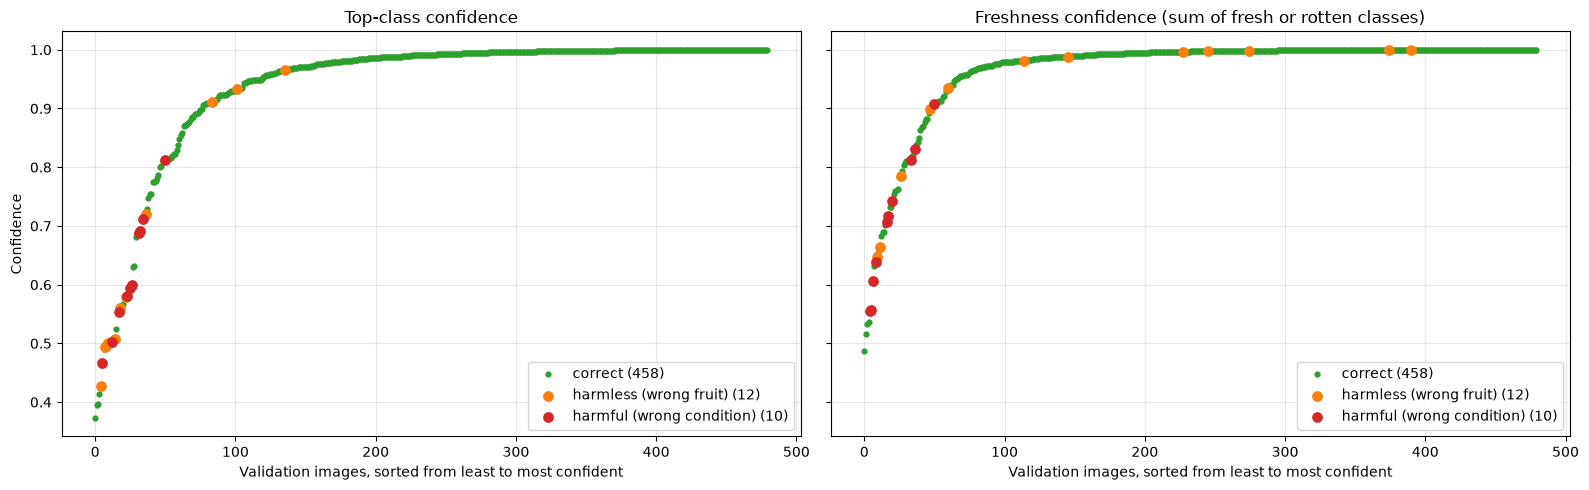

In [17]:
OUTCOME_COLORS = {
    "correct": "tab:green",
    "harmless (wrong fruit)": "tab:orange",
    "harmful (wrong condition)": "tab:red",
}

def plot_sorted_confidence(df, threshold=None):
    """Sort images from least to most confident and colour each point by outcome (like genuine vs impostor scores)."""
    fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
    for ax, column, title in zip(axes,
                                 ["top_class_conf", "freshness_conf"],
                                 ["Top-class confidence", "Freshness confidence (sum of fresh or rotten classes)"]):
        ordered = df.sort_values(column).reset_index(drop=True)
        for outcome, color in OUTCOME_COLORS.items():
            subset = ordered[ordered["outcome"] == outcome]
            size = 12 if outcome == "correct" else 45
            ax.scatter(subset.index, subset[column], s=size, c=color, label=f"{outcome} ({len(subset)})", zorder=3)
        if threshold is not None:
            ax.axhline(threshold, color="black", linestyle="--", label=f"threshold = {threshold}")
        ax.set_title(title)
        ax.set_xlabel("Validation images, sorted from least to most confident")
        ax.grid(alpha=0.3)
        ax.legend(loc="lower right")
    axes[0].set_ylabel("Confidence")
    plt.tight_layout()
    plt.show()

plot_sorted_confidence(val_conf)

In [18]:
def threshold_sweep(df, column, thresholds=np.round(np.arange(0.50, 1.00, 0.05), 2)):
    """For each threshold: how many images are still answered, how accurate those answers are, and which errors are caught."""
    rows = []
    n_harmful = (df["outcome"] == "harmful (wrong condition)").sum()
    n_harmless = (df["outcome"] == "harmless (wrong fruit)").sum()
    for t in thresholds:
        accepted = df[df[column] >= t]
        rejected = df[df[column] < t]
        rows.append({
            "threshold": t,
            "coverage %": 100 * len(accepted) / len(df),
            "accuracy on accepted %": 100 * (accepted["outcome"] == "correct").mean() if len(accepted) else np.nan,
            # what matters to users: is fresh/rotten right? (a harmless wrong-fruit error still counts as right here)
            "freshness right on accepted %": 100 * (accepted["outcome"] != "harmful (wrong condition)").mean() if len(accepted) else np.nan,
            "harmful caught": f"{(rejected['outcome'] == 'harmful (wrong condition)').sum()}/{n_harmful}",
            "harmless caught": f"{(rejected['outcome'] == 'harmless (wrong fruit)').sum()}/{n_harmless}",
            "correct rejected": (rejected["outcome"] == "correct").sum(),
        })
    return pd.DataFrame(rows).round(2)

def choose_threshold(df, column, min_coverage=95.0):
    """Highest threshold that still answers at least `min_coverage`% of images."""
    sweep = threshold_sweep(df, column, thresholds=np.round(np.arange(0.50, 1.00, 0.01), 2))
    return float(sweep[sweep["coverage %"] >= min_coverage]["threshold"].max())

for column in ["top_class_conf", "freshness_conf"]:
    print(f"\n=== {column} ===")
    display(threshold_sweep(val_conf, column))
    print(f"Chosen threshold (coverage >= 95%): {choose_threshold(val_conf, column)}")


=== top_class_conf ===


,threshold,coverage %,accuracy on accepted %,freshness right on accepted %,harmful caught,harmless caught,correct rejected
0,0.50,98.12,96.18,98.09,1/10,3/12,5
1,0.55,96.67,96.98,98.28,2/10,6/12,8
2,0.60,94.38,98.23,99.12,6/10,8/12,13
3,0.65,93.96,98.23,99.11,6/10,8/12,15
4,0.70,92.92,98.65,99.55,8/10,8/12,18
5,0.75,91.88,99.09,99.77,9/10,9/12,21
6,0.80,90.42,99.08,99.77,9/10,9/12,28
7,0.85,87.29,99.28,100.00,10/10,9/12,42
8,0.90,83.96,99.26,100.00,10/10,9/12,58
9,0.95,75.21,99.72,100.00,10/10,11/12,98


Chosen threshold (coverage >= 95%): 0.58

=== freshness_conf ===


,threshold,coverage %,accuracy on accepted %,freshness right on accepted %,harmful caught,harmless caught,correct rejected
0,0.50,99.79,95.41,97.91,0/10,0/12,1
1,0.55,99.17,95.38,97.90,0/10,0/12,4
2,0.60,98.75,95.78,98.31,2/10,0/12,4
3,0.65,97.92,96.38,98.72,4/10,1/12,5
4,0.70,96.88,96.56,98.71,4/10,2/12,9
5,0.75,95.62,97.17,99.35,7/10,2/12,12
6,0.80,94.17,97.35,99.34,7/10,3/12,18
7,0.85,91.67,97.73,99.77,9/10,3/12,28
8,0.90,90.00,97.92,99.77,9/10,4/12,35
9,0.95,86.25,98.31,100.00,10/10,5/12,51


Chosen threshold (coverage >= 95%): 0.76


## Testing on Unseen dataset

In [16]:
def overall_evaluation(data, model:tf.keras.Model):
    """This function runs the model on the test set"""
    performance = model.evaluate(x=data, return_dict=True)
    return performance
model_path = Path().cwd().resolve().parent/"models"/"model"/"freshness-ai.keras"
model = tf.keras.models.load_model(model_path)
print(overall_evaluation(data=test_data, model=model))
    

20/20 ━━━━━━━━━━━━━━━━━━━━ 16s 699ms/step - F1Score: 0.9764 - Precision: 0.9826 - Recall: 0.9719 - accuracy: 0.9766 - loss: 0.0882
{'F1Score': 0.9763789176940918, 'Precision': 0.9826224446296692, 'Recall': 0.971875011920929, 'accuracy': 0.9765625, 'loss': 0.08819004148244858}


In [17]:
def get_per_class_evaluation(data, model:tf.keras.Model):
    """
    This function get per class overall evaluation
    """
    y_true, y_pred, y_prob = [], [], []
    for images, labels in data:
        probabilities = model.predict(images)
        y_prob.extend(probabilities)
        y_pred.extend(np.argmax(probabilities, axis=1))
        y_true.extend(np.argmax(labels.numpy(), axis=1))
    precision = precision_score(y_true=y_true, y_pred=y_pred, average="macro")
    recall = recall_score(y_true=y_true, y_pred=y_pred, average="macro")
    f1 = f1_score(y_true=y_true, y_pred=y_pred, average="macro")
    accuracy = accuracy_score(y_true=y_true, y_pred=y_pred)
    auc_score = roc_auc_score(y_true, y_prob, multi_class="ovr", average="macro")
    conf_matrix = confusion_matrix(y_true=y_true, y_pred=y_pred)
    report = classification_report(y_true, y_pred, target_names=class_names, digits=4)
    return {
        "accuracy":accuracy,
        "precision":precision,
        "recall":recall,
        "f1":f1,
        "auc_score":auc_score,
        "confusion":conf_matrix,
        "report":report,
    }

results = get_per_class_evaluation(data=test_data, model=model)


1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 886ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 836ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 769ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 781ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 719ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 788ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 722ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 709ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 721ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 783ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 720ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 786ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 820ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 782ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 797ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 684ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 695ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 754ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 739ms/step


In [19]:
print(f"Accuracy: {results["accuracy"]}")
print(f"Precision: {results["accuracy"]}")
print(f"Recall: {results["recall"]}")
print(f"F1: {results["f1"]}")
print(results["report"])

Accuracy: 0.9765625
Precision: 0.9765625
Recall: 0.9765625
F1: 0.976378964022779
                    precision    recall  f1-score   support

       fresh_apple     0.9756    1.0000    0.9877        40
      fresh_banana     1.0000    0.9750    0.9873        40
       fresh_grape     0.9750    0.9750    0.9750        40
       fresh_guava     0.9756    1.0000    0.9877        40
      fresh_jujube     0.9524    1.0000    0.9756        40
      fresh_orange     1.0000    1.0000    1.0000        40
 fresh_pomegranate     0.9091    1.0000    0.9524        40
  fresh_strawberry     1.0000    1.0000    1.0000        40
      rotten_apple     0.9722    0.8750    0.9211        40
     rotten_banana     1.0000    1.0000    1.0000        40
      rotten_grape     1.0000    1.0000    1.0000        40
      rotten_guava     0.9500    0.9500    0.9500        40
     rotten_jujube     0.9512    0.9750    0.9630        40
     rotten_orange     1.0000    0.9750    0.9873        40
rotten_pomegranate

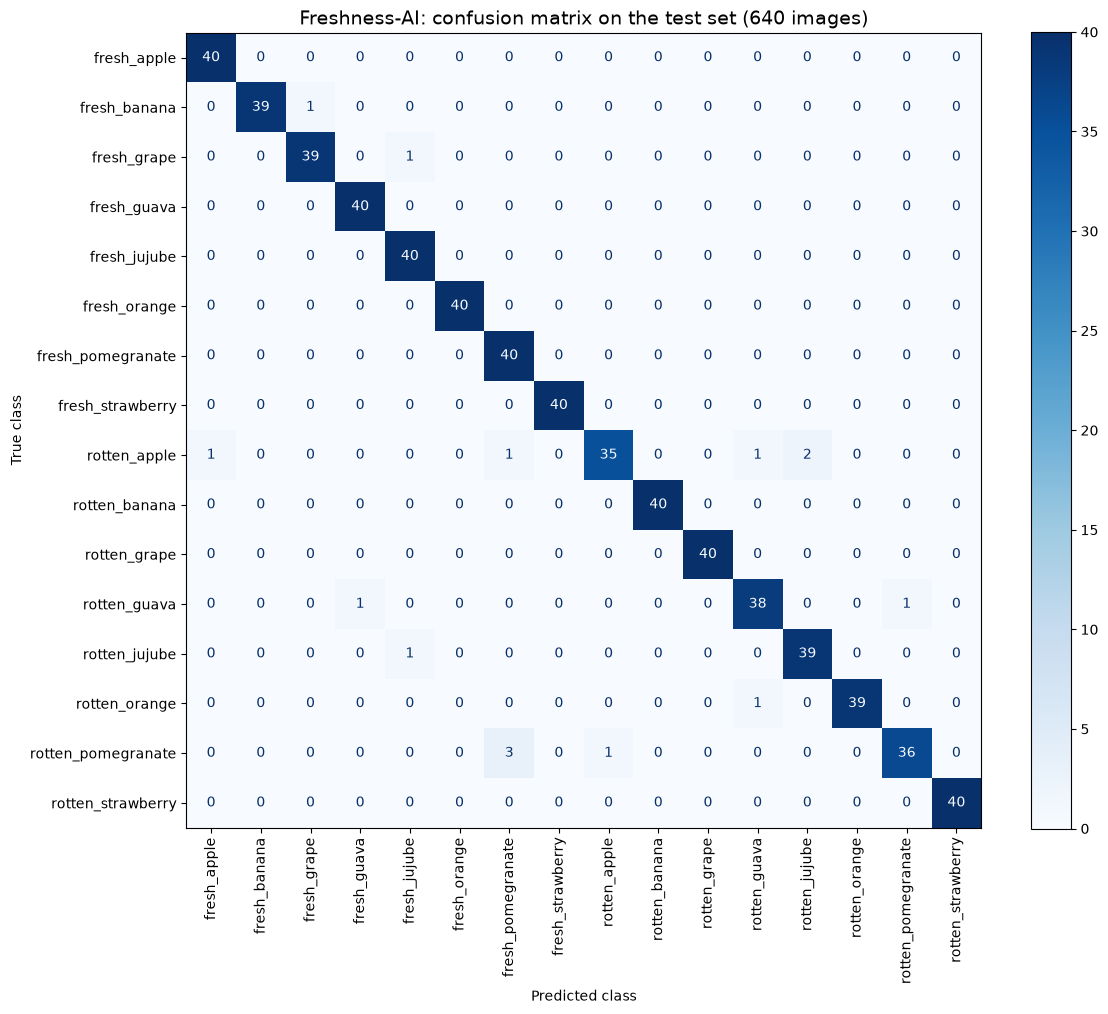

In [20]:
fig, ax = plt.subplots(figsize=(12, 10))
ConfusionMatrixDisplay(
    confusion_matrix=results["confusion"],
    display_labels=class_names,
).plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=90,
    colorbar=True,
    values_format="d",
)
ax.set_title("Freshness-AI: confusion matrix on the test set (640 images)", fontsize=14)
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
plt.tight_layout()
plt.show()


## Grade-CAM

In [27]:
base = next(layer for layer in model.layers if layer.name.startswith("mobilenetv2"))
conv_model = tf.keras.Model(base.inputs, base.get_layer("out_relu").output)

rescale = next(layer for layer in model.layers if isinstance(layer, tf.keras.layers.Rescaling))
gap     = next(layer for layer in model.layers if isinstance(layer, tf.keras.layers.GlobalAveragePooling2D))
dense   = model.layers[-1]


def generate_heatmap(image, class_index=None):
    """
    Grad-CAM heatmap for one image.
    image: H×W×3 array with raw 0–255 pixels (as it comes out of test_data)
    class_index: class to explain; None = the class the model predicts
    Returns (heatmap 7×7 in [0, 1], class_index)
    """
    x = rescale(tf.convert_to_tensor(image[None], dtype=tf.float32))

    with tf.GradientTape() as tape:
        conv = conv_model(x, training=False)
        tape.watch(conv)
        pooled = gap(conv)
        logits = tf.matmul(pooled, dense.kernel) + dense.bias
        if class_index is None:
            class_index = int(tf.argmax(logits[0]))
        score = logits[:, class_index]

    grads = tape.gradient(score, conv)
    weights = tf.reduce_mean(grads, axis=(1, 2))
    cam = tf.reduce_sum(conv * weights[:, None, None, :], axis=-1)[0]
    cam = tf.nn.relu(cam)
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    return cam.numpy(), class_index


def generate_gradcam(image, true_index=None, alpha=0.4):
    """Show the original image next to the Grad-CAM overlay."""
    heatmap, pred_index = generate_heatmap(image)
    heatmap_big = tf.image.resize(heatmap[..., None], image.shape[:2]).numpy().squeeze()

    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    axes[0].imshow(image.astype("uint8"))
    axes[0].set_title(f"True: {class_names[true_index]}" if true_index is not None else "Original")

    axes[1].imshow(image.astype("uint8"))
    axes[1].imshow(heatmap_big, cmap="jet", alpha=alpha)
    correct = true_index is None or true_index == pred_index
    axes[1].set_title(f"Pred: {class_names[pred_index]}", color="green" if correct else "red")

    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


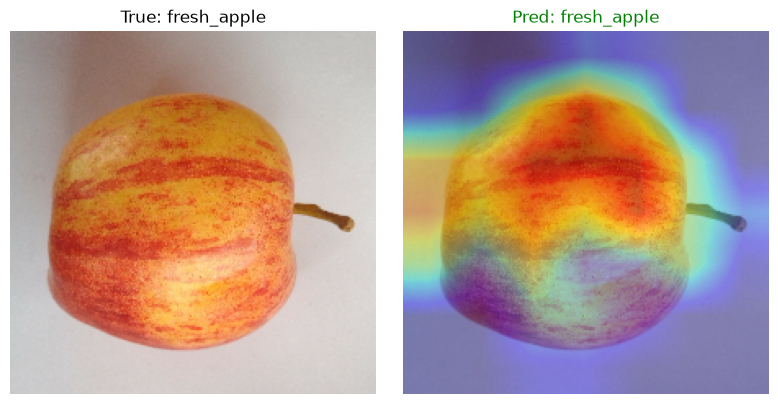

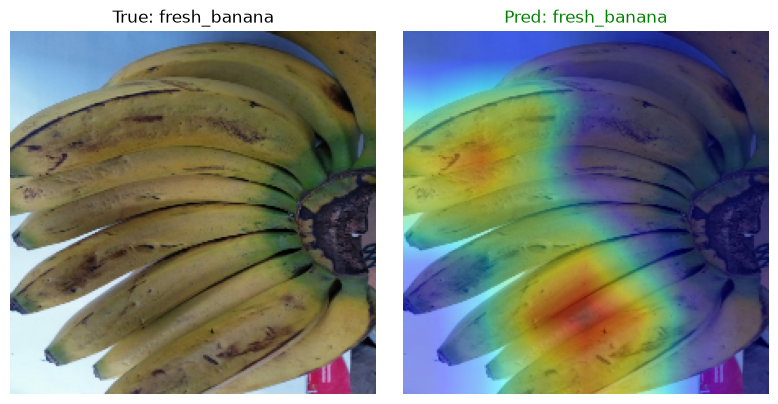

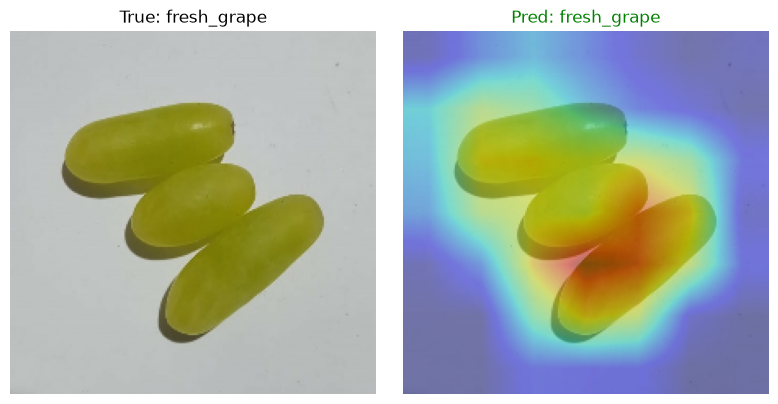

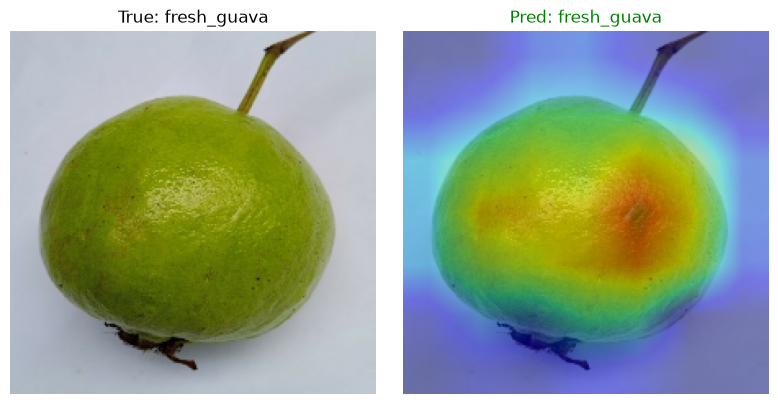

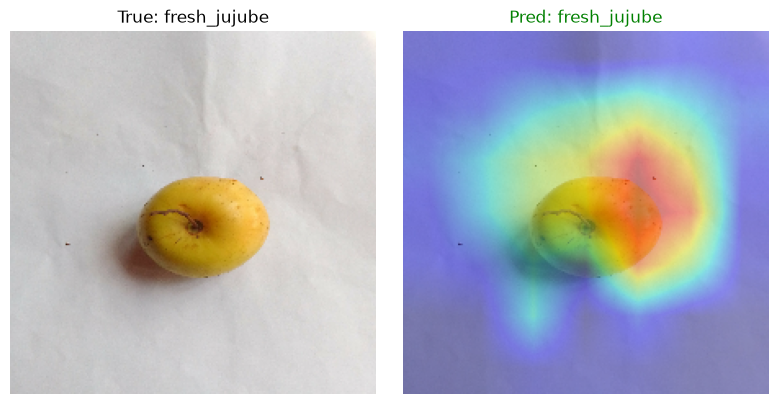

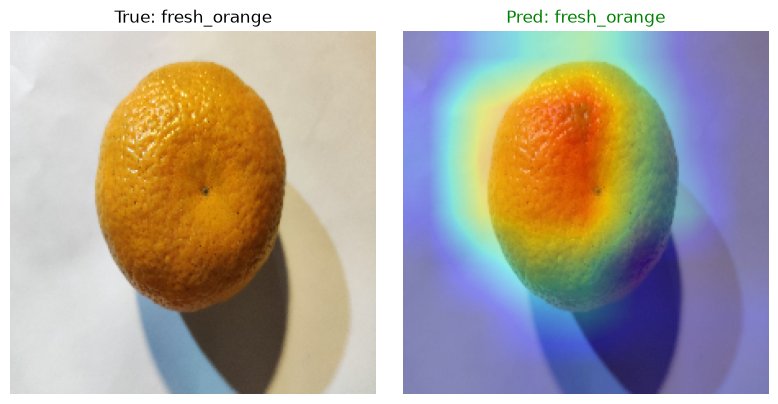

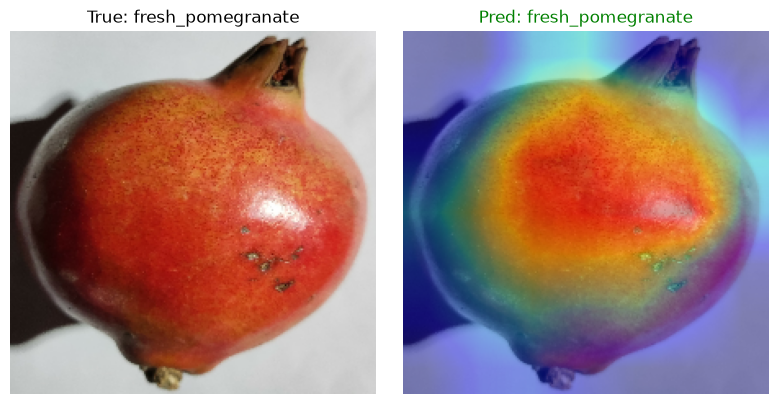

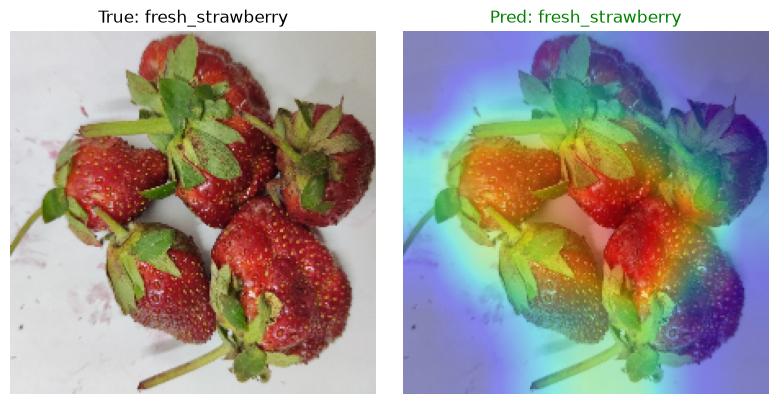

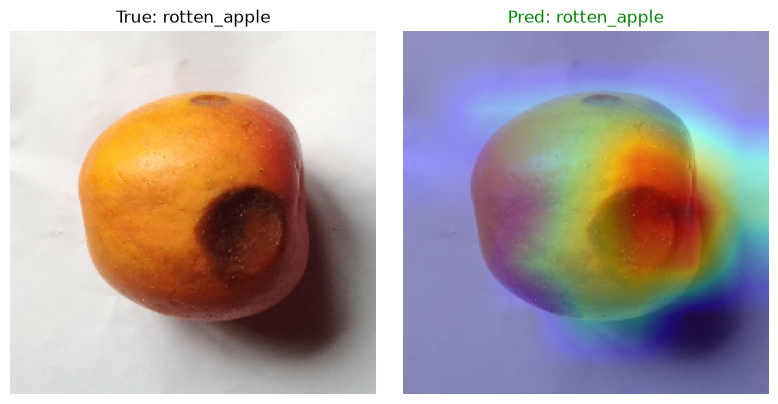

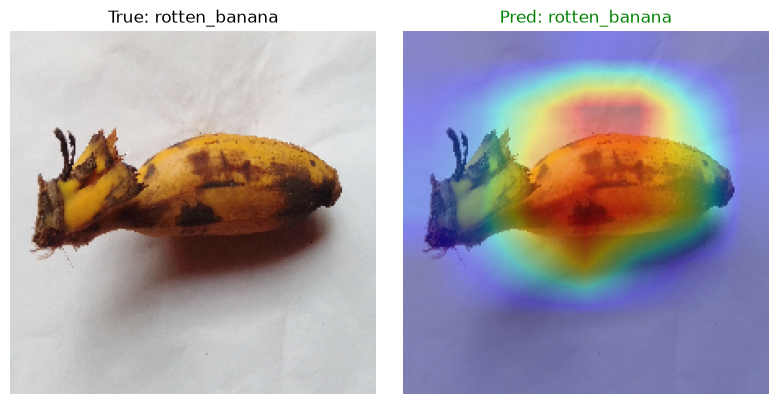

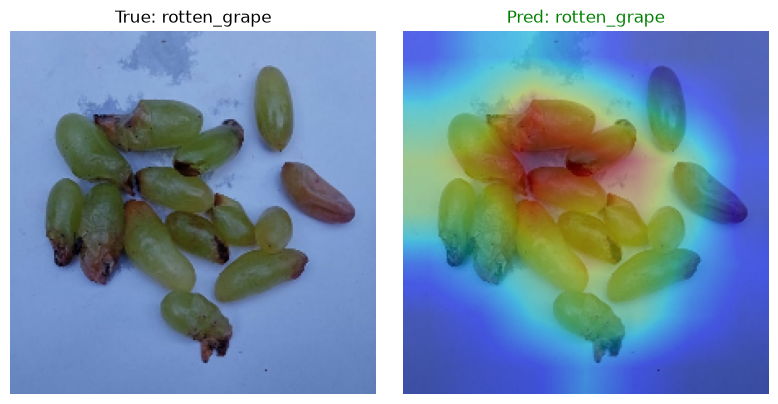

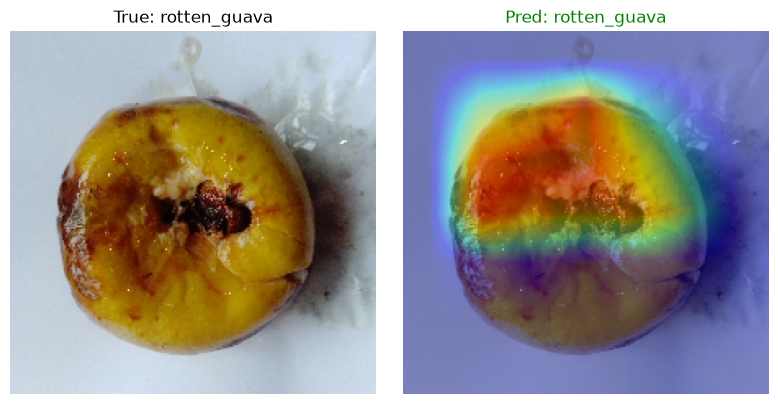

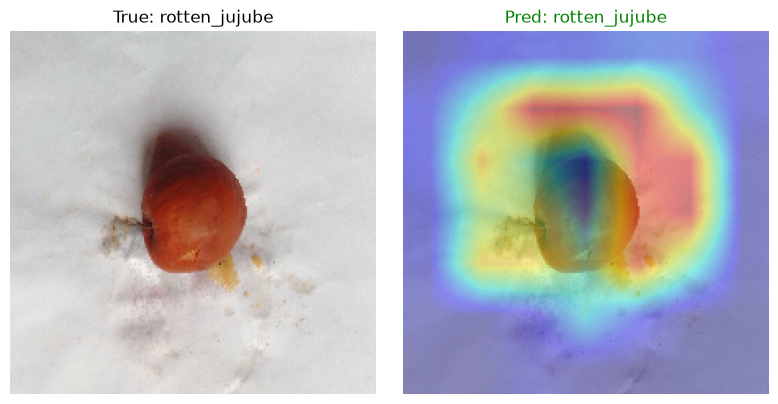

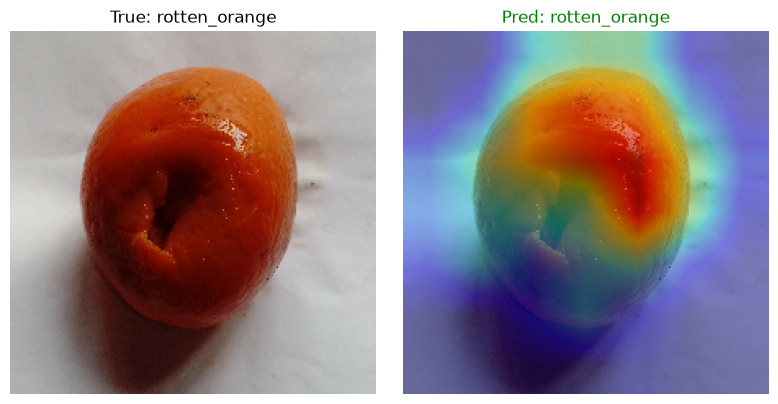

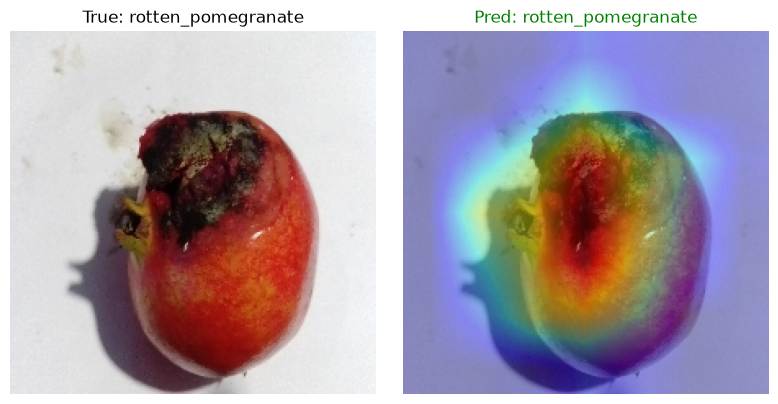

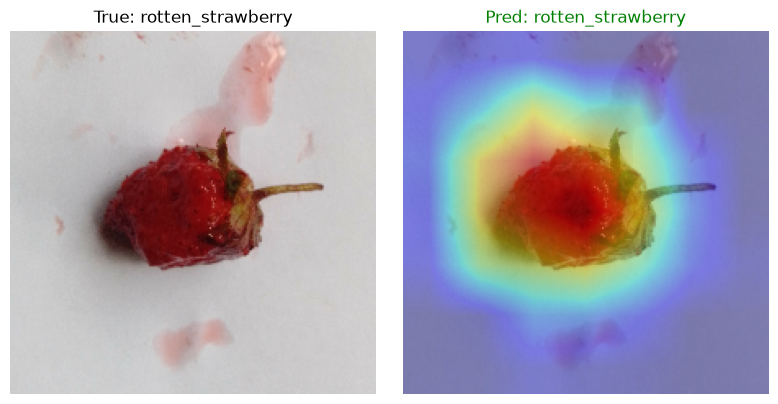

In [28]:
shown = set()
for images, labels in test_data:
    for image, label in zip(images, labels):
        true_index = int(np.argmax(label))
        if true_index not in shown:
            shown.add(true_index)
            generate_gradcam(image=image.numpy(), true_index=true_index)
    if len(shown) == len(class_names):
        break

## Step 5: Testing model on unseen data (about 640 images)

In [71]:
%load_ext tensorboard
%tensorboard --logdir logs

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


Reusing TensorBoard on port 6006 (pid 23359), started 1:42:08 ago. (Use '!kill 23359' to kill it.)

## References
1. Deng, J., Dong, W., Socher, R., Li, L.-J., Li, K., & Fei-Fei, L. (2009). ImageNet: A large-scale hierarchical image database. In 2009 IEEE Conference on Computer Vision and Pattern Recognition (pp. 248–255). IEEE. https://doi.org/10.1109/CVPR.2009.5206848

2. He, K., Zhang, X., Ren, S., & Sun, J. (2016). Deep residual learning for image recognition. In Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition (pp. 770–778). IEEE. https://doi.org/10.1109/CVPR.2016.90

3. Keras Team. (n.d.). Keras applications. Keras. Retrieved November 19, 2026, from https://keras.io/api/applications/

4. Russakovsky, O., Deng, J., Su, H., Krause, J., Satheesh, S., Ma, S., Huang, Z., Karpathy, A., Khosla, A., Bernstein, M., Berg, A. C., & Fei-Fei, L. (2015). ImageNet large scale visual recognition challenge. International Journal of Computer Vision, 115(3), 211–252. https://doi.org/10.1007/s11263-015-0816-y

5. Sandler, M., Howard, A., Zhu, M., Zhmoginov, A., & Chen, L.-C. (2018). MobileNetV2: Inverted residuals and linear bottlenecks. In Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition (pp. 4510–4520). IEEE. https://doi.org/10.1109/CVPR.2018.00474

6. TensorFlow. (n.d.). Transfer learning and fine-tuning. Retrieved November 19, 2026, from https://www.tensorflow.org/tutorials/images/transfer_learning

7. Yosinski, J., Clune, J., Bengio, Y., & Lipson, H. (2014). How transferable are features in deep neural networks? In Advances in Neural Information Processing Systems 27 (pp. 3320–3328). Curran Associates.